# Figure S22 - Radius-of-gyration convergence across (GV)20-(PGSK)10 replicates

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** Violin plots of the per-frame radius of gyration for each of the 20 (GV)20-(PGSK)10 replicates, annotated with a one-way ANOVA. The point of the figure is a contrast: by a *global* measure like Rg the replicates look converged, yet Figure 6 shows that *locally* the (GV)20 half is trapped in replicate-specific conformations. Global convergence is necessary but not sufficient.

**A correction to the published statistic.** The paper reports an ANOVA p-value of 0.96 ("means not significantly different"). That number came from grouping the data by *frame* rather than by replicate - the original notebook built a `(replicates x frames)` DataFrame and iterated over its transpose, producing 3200 groups of 20 values. Grouped correctly (20 replicates x 3200 frames) the same test gives p ≈ 0: with thousands of frames per replicate even a fraction of an Ångström difference in mean Rg is "significant", and because consecutive frames are correlated the test is anti-conservative on top of that. The more useful numbers are the ones printed below: the replicate means span roughly 23-26 Å, a spread (sd ≈ 0.6 Å) that is small compared with the ≈ 4.6 Å width of each replicate's own Rg distribution. That is the sense in which the replicates are globally converged, and the figure is unchanged.

**Data.** The same 20 FH replicates used in Figure 6 (3200 frames each after truncation).

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)
from scipy import stats

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Load and compute Rg per replicate

In [2]:
polyGV = load_system("polyGV_PGSK/full", "polyGV_PGSK/ev", num_replicates=20,
                     method="2D angle distributions", truncate=True)
rgs = np.array([t.proteinTrajectoryList[0].get_radius_of_gyration() for t in polyGV.trajs])
print("Rg array (replicates, frames):", rgs.shape)

20 FH replicates, 20 EV replicates


Successfully truncated.
                The shortest trajectory is: 3200 frames.                All trajectories truncated to 3200


Rg array (replicates, frames): (20, 3200)


## Statistics

Bartlett's test checks whether the replicate variances are equal (a prerequisite for the classical ANOVA); the ANOVA then asks whether any replicate has a different mean Rg. Each replicate is one group. The by-frame grouping that produced the published p = 0.96 is also computed, for the record.

In [3]:
# one group per replicate (rows of rgs), each holding that replicate's frames
bartlett_stat, bartlett_p = stats.bartlett(*rgs)
f_stat, anova_p = stats.f_oneway(*rgs)
print(f"Bartlett p = {bartlett_p:.3g}   ANOVA p = {anova_p:.3g}   (20 replicates x {rgs.shape[1]} frames)")

# the paper's p = 0.96 corresponds to grouping by frame instead (3200 groups of 20)
_, anova_p_by_frame = stats.f_oneway(*rgs.T)
print(f"ANOVA p grouped by frame (as in the published notebook) = {anova_p_by_frame:.2f}")

replicate_means = rgs.mean(axis=1)
print(f"replicate mean Rg: {replicate_means.min():.2f}-{replicate_means.max():.2f} Å "
      f"(sd across replicates {replicate_means.std():.2f} Å); "
      f"mean within-replicate sd {rgs.std(axis=1).mean():.2f} Å")

Bartlett p = 3.87e-22   ANOVA p = 3.18e-233   (20 replicates x 3200 frames)
ANOVA p grouped by frame (as in the published notebook) = 0.96
replicate mean Rg: 23.10-25.97 Å (sd across replicates 0.62 Å); mean within-replicate sd 4.57 Å


## Plot

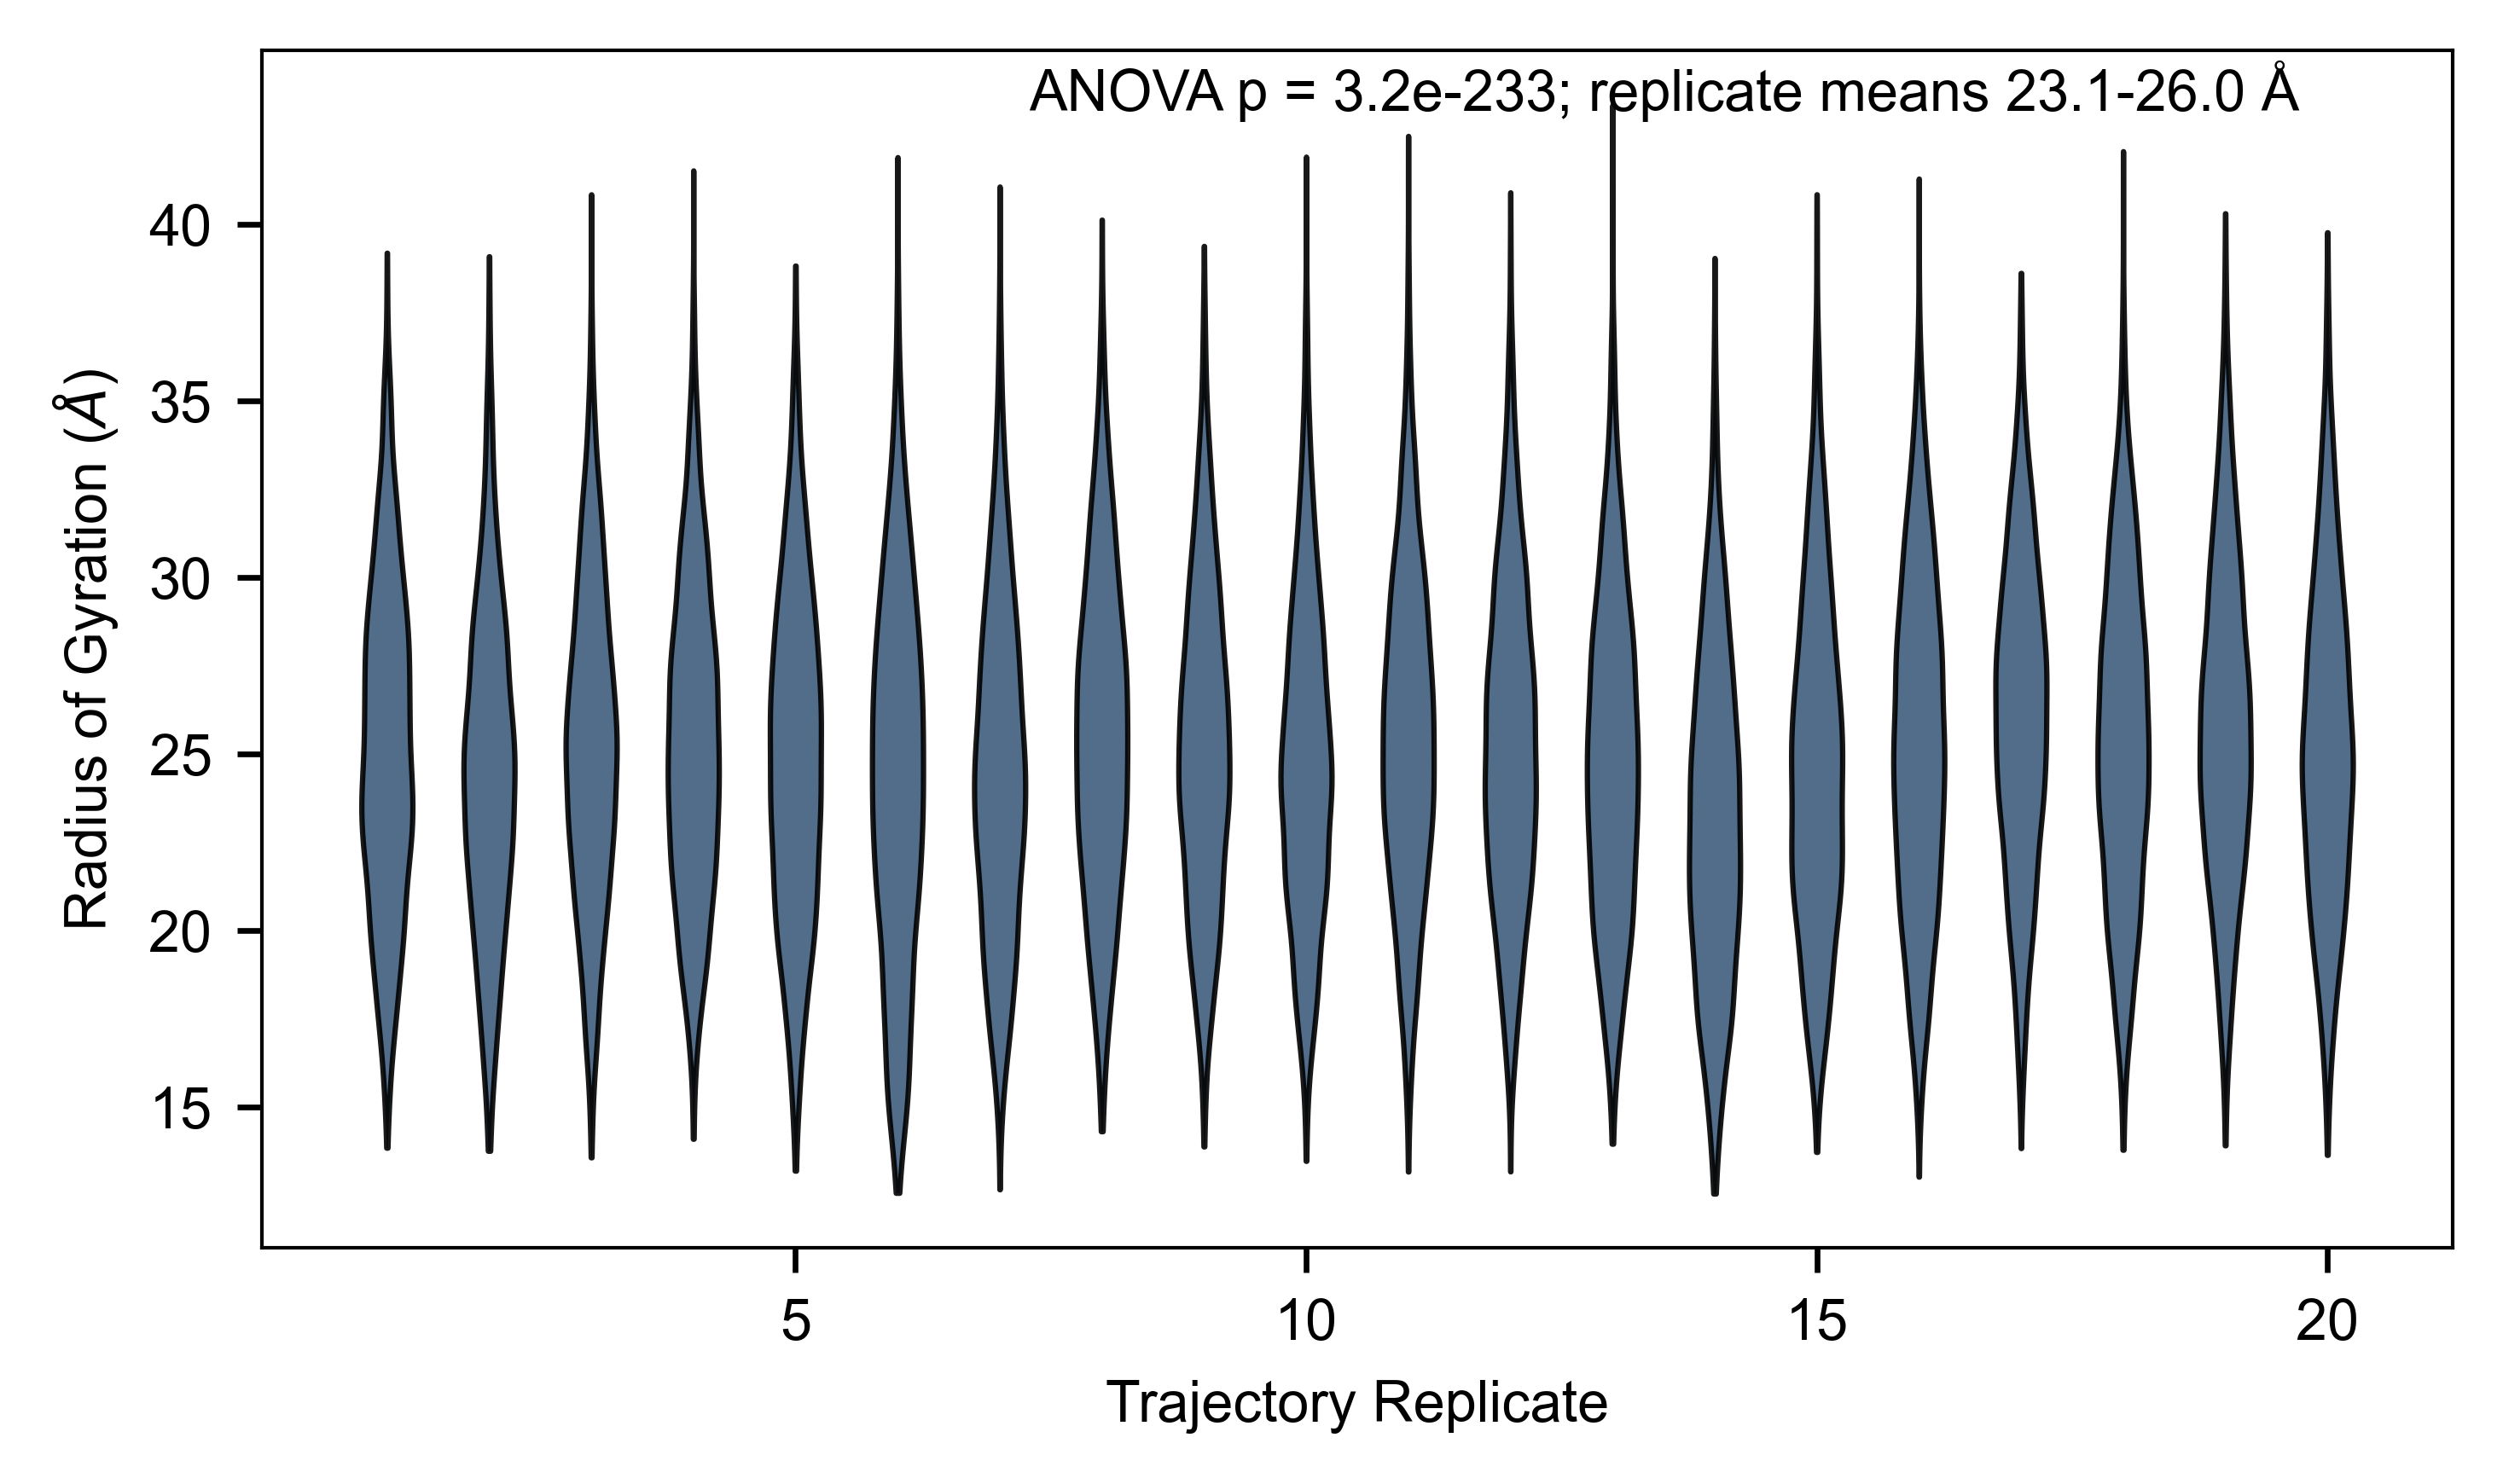

In [4]:
fontsize = 8
n_reps = rgs.shape[0]
fig, ax = plt.subplots(figsize=(5, 3), facecolor="w", dpi=300)
parts = ax.violinplot(list(rgs), positions=np.arange(1, n_reps + 1), showmeans=False, showextrema=False)
for body in parts["bodies"]:
    body.set_facecolor("#3F5D7D"); body.set_edgecolor("k"); body.set_alpha(0.9); body.set_linewidth(0.75)
ax.set_xlabel("Trajectory Replicate", fontsize=fontsize)
ax.set_ylabel(r"Radius of Gyration ($\AA$)", fontsize=fontsize)
ax.set_xticks(np.arange(5, n_reps + 1, 5))
ax.tick_params(labelsize=fontsize)
ax.annotate(f"ANOVA p = {anova_p:.1e}; replicate means {replicate_means.min():.1f}-{replicate_means.max():.1f} Å",
            xy=(0.35, 0.95), xycoords="axes fraction", fontsize=fontsize)
fig.tight_layout()
fig.savefig(figure_path("si_figures", "polyGV_rg_anova.pdf"), dpi=400)